In [72]:
import pandas as pd
import spam_utils as spam

# Show all rows
pd.set_option('display.max_rows', None)

# Show all columns
pd.set_option('display.max_columns', None)

# (Optional) Show full text in cells
pd.set_option('display.max_colwidth', None)

In [68]:
df1 = pd.read_csv('spam_train1.csv')
df2 = pd.read_csv('spam_train2.csv')

# Select the relevant columns from each dataset
df1 = df1[['v1', 'v2']].copy()
df2 = df2[['label', 'text']].copy()

# Give both datasets consistent column names
df1.columns = ['label', 'text']

df = pd.concat([df1, df2], ignore_index=True)

display("Original rows:", len(df))
display("Duplicates:", df.duplicated(subset='text').sum())

conflicts = df.groupby('text')['label'].nunique()
conflicts = conflicts[conflicts > 1]

display(conflicts)

if len(conflicts):
    raise ValueError(
        f"{len(conflicts)} duplicate emails have conflicting labels."
    )

df = df.drop_duplicates(subset='text').reset_index(drop=True)

pd.DataFrame(df.groupby('text')['label'].nunique())

'Original rows:'

4296

'Duplicates:'

np.int64(102)

Series([], Name: label, dtype: int64)

,label
text,
"came to look at the flat, seems ok, in his 50s? * Is away alot wiv work. Got woman coming at 6.30 too.",1
gonna let me know cos comes bak from holiday that day. is coming. Don't4get2text me number.,1
&lt;#&gt; great loxahatchee xmas tree burning update: you can totally see stars here,1
"&lt;#&gt; is fast approaching. So, Wish u a very Happy New Year Happy Sankranti Happy republic day Happy Valentines Day Happy Shivratri Happy Ugadi Happy Fools day Happy May Day Happy Independence Day, Happy Friendship,Mother,Father,Teachers,Childrens Day, &amp; HAPPY BIRTHDAY 4 U. Happy Ganesh festival Happy Dasara Happy Diwali Happy Christmas &lt;#&gt; Good Mornings Afternoons, Evenings Nights. RememberI AM the first to WISHING U ALL THESE...your's Raj",1
&lt;#&gt; w jetton ave if you forgot,1
...,...
ÌÏ no home work to do meh...,1
ÌÏ still attending da talks?,1
ÌÏ still got lessons? ÌÏ in sch?,1


In [51]:
X = df['text']
y = df['label']

results, predictions = spam.evaluate_models(X, y)

display(results)

,Model,Accuracy,Macro-F1,Spam Precision,Spam Recall,Spam F1,Ham FPR
0,Naive Bayes,0.8715 ± 0.0051,0.7496 ± 0.0132,1.0000 ± 0.0000,0.4038 ± 0.0229,0.5750 ± 0.0237,0.0000 ± 0.0000
1,Logistic Regression,0.9130 ± 0.0045,0.8497 ± 0.0089,0.9737 ± 0.0085,0.6129 ± 0.0196,0.7521 ± 0.0151,0.0046 ± 0.0015
2,SVC,0.9392 ± 0.0048,0.9005 ± 0.0088,0.9808 ± 0.0062,0.7323 ± 0.0232,0.8384 ± 0.0148,0.0040 ± 0.0014


In [73]:
fp, fn = spam.analyze_errors(
    X, y, predictions['SVC']
)

display(fp)
display(fn)

,Email,Actual,Predicted
179,"Hi, Mobile no. &lt;#&gt; has added you in their contact list on www.fullonsms.com It s a great place to send free sms to people For more visit fullonsms.com",ham,spam
320,On the road so cant txt,ham,spam
373,I to am looking forward to all the sex cuddling.. Only two more sleeps,ham,spam
573,How do you guys go to see movies on your side.,ham,spam
1416,JADE ITS PAUL. Y DIDNåÕT U TXT ME? DO U REMEMBER ME FROM BARMED? I WANT 2 TALK 2 U! TXT ME,ham,spam
1935,.Please charge my mobile when you get up in morning.,ham,spam
2331,Subject: holiday party - save the date\r\nplease click on the link below\r\nsave the date,ham,spam
2423,"Subject: registration welcome email\r\nthank you for registering at citibank account online . you now have\r\nfree access , 24 hours a day , to your citibank account information .\r\nsign - on at https : / / www . accountonline . com / cb / login . dcl to view your\r\nstatements , monitor your unbilled activity and enroll in one of our\r\nelectronic payment options . while you ' re there , check out these\r\ngreat features :\r\nall - electronic - enroll today and make your paper statement a\r\nthing of the past . view it online instead . then , pay your bill\r\nonline with click - to - pay or autopay .\r\nexpress request - manage your citibank account information from\r\nyour computer . change your address , request a credit line\r\nincrease , order a replacement card and more .\r\ncitibank bill manager - receive and pay all of your bills online .\r\nsecure messaging - have a question ? use our secure message pad to\r\ncorrespond safely with our customer care center .\r\nthe citibank toolbar - download this free software * and enjoy one\r\nclick access to account online and other password protected\r\nwebsites . plus , the citibank toolbar will fill online shopping\r\nforms with just one click !\r\nonce again , thanks for registering . we hope you visit account online\r\nat https : / / www . accountonline . com / cb / login . dcl again soon .\r\n* at point of download see terms and conditions governing use\r\nof software .\r\nfor your records , we have listed your user id and email address\r\nbelow .\r\nuser id : colioquake\r\nemail address : dfarmer @ enron . com\r\nto learn about citibank privacy , read our privacy promise at\r\nthis message is for information purposes only . please do not reply to\r\nus at this email address - - it is unattended , and we will not respond .\r\nuse the secure message center in help / contact us at account online .",ham,spam
2813,"Subject: young families egg hunt\r\nbammelyoungfamilies\r\n- - - - - - - - - - - - - - - - - - - - - - - - - - - listbot sponsor - - - - - - - - - - - - - - - - - - - - - - - - - -\r\nstart your own free email list at http : / / www . listbot . com / links / joinlb\r\nto unsubscribe , write to - unsubscribe @ listbot . com",ham,spam
3252,"Subject: your amazon . com order ( # 102 - 6820014 - 8227326 )\r\ngreetings from amazon . com .\r\nwe thought you ' d like to know that we shipped your items today ,\r\nand that this completes your order .\r\nthanks for shopping at amazon . com , and we hope to see you again soon .\r\nyou can track the status of this order , and all your orders , online by\r\nvisiting "" your account "" page at http : / / www . amazon . com / your - account .\r\nthere you can :\r\n* track order and shipment status\r\n* review estimated delivery dates\r\n* cancel unshipped items\r\n* return items\r\n* and do much more\r\nthe following items were included in this shipment :\r\nqty item price shipped subtotal\r\n1 tonka mighty front loader $ 19 . 99 1 $ 19 . 99\r\nitem subtotal : $ 19 . 99\r\nshipping & handling : $ 0 . 00\r\ntotal : $ 19 . 99\r\nthis shipment was sent to :\r\ndaren farmer\r\n2747 meadowtree\r\nspring tx 77388\r\nvia ups ground ( 3 - 7 business days ) .\r\nfor your reference , the number you can use to track your package is lza 41 wl 90316789627 . you can refer to our web site ' s help pag

,Email,Actual,Predicted
85,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Txt XXX SLO(4msgs),spam,ham
91,1000's of girls many local 2 u who r virgins 2 this & r ready 2 4fil ur every sexual need. Can u 4fil theirs? text CUTE to 69911(å£1.50p. m),spam,ham
96,"TheMob>Hit the link to get a premium Pink Panther game, the new no. 1 from Sugababes, a crazy Zebra animation or a badass Hoody wallpaper-all 4 FREE!",spam,ham
170,Want explicit SEX in 30 secs? Ring 02073162414 now! Costs 20p/min,spam,ham
193,ASKED 3MOBILE IF 0870 CHATLINES INCLU IN FREE MINS. INDIA CUST SERVs SED YES. L8ER GOT MEGA BILL. 3 DONT GIV A SHIT. BAILIFF DUE IN DAYS. I O å£250 3 WANT å£800,spam,ham
207,You have 1 new voicemail. Please call 08719181503,spam,ham
318,500 free text msgs. Just text ok to 80488 and we'll credit your account,spam,ham
332,"0A$NETWORKS allow companies to bill for SMS, so they are responsible for their \suppliers\""",spam,ham
356,Ur balance is now å£500. Ur next question is: Who sang 'Uptown Girl' in the 80's ? 2 answer txt ur ANSWER to 83600. Good luck!,spam,ham
403,"Win the newest ÛÏHarry Potter and the Order of the Phoenix (Book 5) reply HARRY, answer 5 questions - chance to be the first among readers!",spam,ham


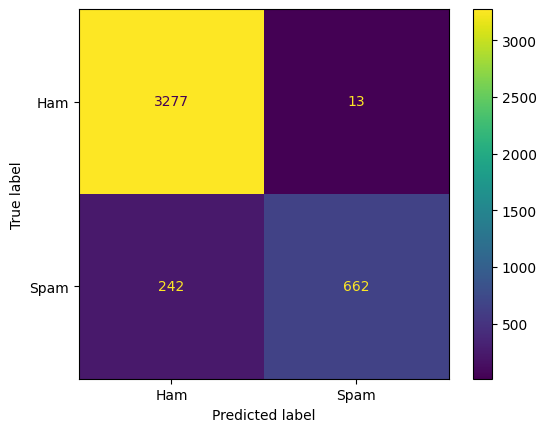

In [53]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y,
    predictions['SVC'],
    labels=['ham', 'spam'],
    display_labels=['Ham', 'Spam']
)

In [54]:
final_model = spam.train_final_model(X, y, 'SVC')

In [55]:
test_df, test_predictions = spam.predict_test(
    final_model,
    'spam_test.csv',
    text_column='message'
)

In [69]:
output = test_df.copy()
output['label'] = test_predictions

output.to_csv('Classifications_Spam.csv', index=False)